# 05 · Model Training and Hyperparameter Tuning

Four models are compared against three baselines:

| | Model | Type | Needs scaling? |
|---|---|---|---|
| ML | **Ridge regression** | linear, L2-regularised | yes |
| ML | **Random Forest** | bagged decision trees | no |
| ML | **XGBoost** | gradient-boosted trees | no |
| ML | **SVR (RBF kernel)** | kernel method | yes |
| Baseline | Climatology | predict anomaly = 0 | – |
| Baseline | Persistence | anomaly(t+1) = anomaly(t) | – |
| Baseline | Damped persistence (AR(1)) | anomaly(t+1) = φ·anomaly(t) | – |

**Tuning protocol** (details and reasoning in `src/models.py`): expanding-window time-series CV with 4 folds inside 2000–2022. The best mean-RMSE configuration is refitted on 2000–2022. **The 2023–2025 test set is not used anywhere in this notebook**; it is evaluated in notebook 06.

### Development notes: two problems found and fixed

1. **A single validation block is too noisy.** The master document's 2020–2022 validation split is fold 4 here. Anomalies are spatially correlated, so one 3-year block is only about 36 effective samples, and tuning on it alone gave unstable choices. The 4-fold design keeps that block and adds three earlier ones.
2. **Hidden leakage inside CV.** The anomalies in `features.parquet` use the 2000–2019 climatology. That is safe for the final test (2023–2025), but in folds 1–3 the validation years lie *inside* 2000–2019, so the training anomalies would carry information about the validation period's mean. An ablation exposed it: a model's intercept was absorbing an artificial mean shift. **Fix:** every fold recomputes the climatology, all anomaly features and the target from its own training years (`M.make_cv_folds`). Each fold now reproduces a real forecast, just like the final test.

In [1]:
import sys, time; sys.path.insert(0, "..")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from src import config as C, features as F, models as M, plotting as V, preprocessing as P
V.set_style(); pd.set_option("display.width", 170); pd.set_option("display.max_colwidth", 120)
feat = F.load_features()
dev = feat[feat["split"] != "test"].reset_index(drop=True)      # 2000-2022: tuning + final training
test = feat[feat["split"] == "test"].reset_index(drop=True)     # 2023-2025: untouched until notebook 06
print("development rows:", len(dev), "| test rows (held out):", len(test))
folds = M.make_cv_folds(P.load_processed())                      # fold-specific climatology + features
pd.DataFrame([{"fold": f["fold"], "climatology years": f"{C.START_YEAR}–{f['val_years'][0] - 1}",
               "train target years": f"{f['train'].target_year.min()}–{f['train'].target_year.max()}",
               "validate target years": f"{f['val_years'][0]}–{f['val_years'][1]}",
               "train rows": len(f["train"]), "validation rows": len(f["val"]),
               "mean train target (°C)": round(f["train"][F.TARGET].mean(), 3),
               "mean validation target (°C)": round(f["val"][F.TARGET].mean(), 3)} for f in folds])

development rows: 34020 | test rows (held out): 4536


,fold,climatology years,train target years,validate target years,train rows,validation rows,mean train target (°C),mean validation target (°C)
0,1,2000–2010,2000–2010,2011–2013,15876,4536,-0.011,-0.750
1,2,2000–2013,2000–2013,2014–2016,20412,4536,-0.017,-0.235
2,3,2000–2016,2000–2016,2017–2019,24948,4536,-0.017,0.054
3,4,2000–2019,2000–2019,2020–2022,29484,4536,-0.014,0.016


## 1. Baselines on the same CV folds

The models are judged against these numbers. For damped persistence, φ is re-fitted on each fold's training rows.

In [2]:
rows = []
for f in folds:
    phi = M.fit_damped_phi(f["train"])
    v = f["val"]
    for name, p in M.baseline_predictions(v, phi).items():
        rows.append({"fold": f["fold"], "model": name, "val_rmse": np.sqrt(np.mean((p - v[F.TARGET]) ** 2))})
    rows[-1]["phi"] = phi
cv_base = pd.DataFrame(rows)
cv_base.pivot(index="model", columns="fold", values="val_rmse").assign(mean=lambda x: x.mean(axis=1)).loc[M.BASELINE_ORDER].round(3)

fold,1,2,3,4,mean
model,,,,,
Climatology,1.563,1.620,1.467,1.875,1.631
Persistence,1.730,1.696,1.769,2.024,1.805
Damped persistence,1.462,1.499,1.401,1.718,1.520


In [3]:
phi_dev = M.fit_damped_phi(dev)
print(f"Damped-persistence coefficient fitted on 2000-2022: phi = {phi_dev:.3f}")
print("(phi < 1 means anomalies decay: on average only this fraction of this month's anomaly carries into next month)")

Damped-persistence coefficient fitted on 2000-2022: phi = 0.310
(phi < 1 means anomalies decay: on average only this fraction of this month's anomaly carries into next month)


## 2. Hyperparameter search

| Model | Search | Space | Configurations |
|---|---|---|---|
| Ridge | grid | α ∈ 10⁻² … 10⁷ (19 values, log scale) | 19 |
| Random Forest | grid | min_samples_leaf ∈ {25, 50, 100, 400, 1000}, max_features ∈ {0.05, 0.1, 0.2, 0.4}, max_depth ∈ {4, 6, None} | 60 |
| XGBoost | random search | learning_rate 0.002–0.1, max_depth 1–6, min_child_weight 5–2000, subsample, colsample_bytree, L2 penalty λ 0.1–1000 | 30 |
| SVR | grid | C ∈ {0.01, 0.1, 1}, ε ∈ {0.5, 1.0}, γ ∈ {scale, 0.01} | 12 |

Each configuration is scored on all 4 folds (= one fit per fold). SVR training time grows roughly with the square of the row count, so its search uses a random subsample of 8,000 training rows per fold. The final SVR is fitted on all rows.

The searches deliberately include **strongly regularised** settings: large α, large leaf sizes, small learning rates and large ε. The EDA showed the predictable signal is weak, so the main risk is fitting noise.

*Search-range revisions:* in earlier runs, the best Ridge α (10⁴) and the best Random Forest settings (first the largest leaf size, then the smallest leaf size and feature fraction) sat on the **edge** of their grids. That means the optimum could lie outside the searched range. The ranges were widened (above), and the cell after the search verifies that every selected value lies strictly inside its range.

In [4]:
best_params, cv_tables, timings = {}, {}, {}
C.MODELS_DIR.mkdir(exist_ok=True); (C.ROOT / "reports").mkdir(exist_ok=True)
for name in M.MODEL_ORDER:
    params, res, secs = M.tune(name, folds)
    best_params[name], cv_tables[name], timings[name] = params, res, secs
    res.drop(columns=[c for c in res.columns if c.endswith("_test_score")]) \
       .to_csv(C.ROOT / "reports" / f"cv_results_{M.slug(name)}.csv", index=False)
    print(f"{name:14s} {len(res):3d} configs in {secs/60:5.1f} min | best mean CV RMSE {res['mean_val_rmse'].iloc[0]:.4f} | {params}")
M.save_params(best_params)

Ridge           19 configs in   0.4 min | best mean CV RMSE 1.5312 | {'model__alpha': np.float64(10000.0)}


Random Forest   60 configs in  10.5 min | best mean CV RMSE 1.5387 | {'max_depth': 4, 'max_features': 0.2, 'min_samples_leaf': 100}


XGBoost         30 configs in   3.5 min | best mean CV RMSE 1.5451 | {'colsample_bytree': np.float64(0.41770579950770825), 'learning_rate': np.float64(0.0252020624017107), 'max_depth': 1, 'min_child_weight': 632, 'reg_lambda': np.float64(2.572026419788233), 'subsample': np.float64(0.6523906290790145)}


SVR             12 configs in   4.4 min | best mean CV RMSE 1.5281 | {'model__C': 0.1, 'model__epsilon': 0.5, 'model__gamma': 0.01}


In [5]:
# Top 5 configurations per model. The gap between train and validation RMSE shows over-fitting.
for name in M.MODEL_ORDER:
    t = cv_tables[name]
    show = t[["params", "mean_train_rmse", "mean_val_rmse"]].head(5).copy()
    show["overfit gap"] = show["mean_val_rmse"] - show["mean_train_rmse"]
    print(f"\n=== {name} ==="); print(show.round(4).to_string(index=False))


=== Ridge ===
                              params  mean_train_rmse  mean_val_rmse  overfit gap
           {'model__alpha': 10000.0}           1.4044         1.5312       0.1268
{'model__alpha': 31622.776601683792}           1.4177         1.5352       0.1175
{'model__alpha': 3162.2776601683795}           1.3971         1.5372       0.1400
            {'model__alpha': 1000.0}           1.3947         1.5435       0.1488
{'model__alpha': 316.22776601683796}           1.3942         1.5467       0.1525

=== Random Forest ===
                                                        params  mean_train_rmse  mean_val_rmse  overfit gap
{'max_depth': 4, 'max_features': 0.2, 'min_samples_leaf': 100}           1.3310         1.5387       0.2076
{'max_depth': 4, 'max_features': 0.2, 'min_samples_leaf': 400}           1.3708         1.5389       0.1681
 {'max_depth': 4, 'max_features': 0.2, 'min_samples_leaf': 50}           1.3191         1.5400       0.2209
 {'max_depth': 6, 'max_features': 0.1,

In [6]:
# Edge check: a selected value on the boundary of a grid means the search range was too narrow
rows = []
for name in M.MODEL_ORDER:
    kind, space = M.SEARCH[name]
    if kind != "grid":
        continue
    for p, grid in space.items():
        nums = [g for g in grid if isinstance(g, (int, float)) and g is not None]
        v = best_params[name][p]
        on_edge = isinstance(v, (int, float)) and len(nums) > 2 and v in (min(nums), max(nums))
        rows.append({"model": name, "parameter": p, "selected": v, "grid": grid, "on edge?": on_edge})
pd.DataFrame(rows)

,model,parameter,selected,grid,on edge?
0,Ridge,model__alpha,10000.00,"[0.01, 0.031623, 0.1, 0.316228, 1.0, 3.162278, 10.0, 31.622777, 100.0, 316.227766, 1000.0, 3162.27766, 10000.0, 3162...",False
1,Random Forest,min_samples_leaf,100.00,"[25, 50, 100, 400, 1000]",False
2,Random Forest,max_features,0.20,"[0.05, 0.1, 0.2, 0.4]",False
3,Random Forest,max_depth,4.00,"[4, 6, None]",False
4,SVR,model__C,0.10,"[0.01, 0.1, 1.0]",False
5,SVR,model__epsilon,0.50,"[0.5, 1.0]",False
6,SVR,model__gamma,0.01,"[scale, 0.01]",False


## 3. What the tuning curves show

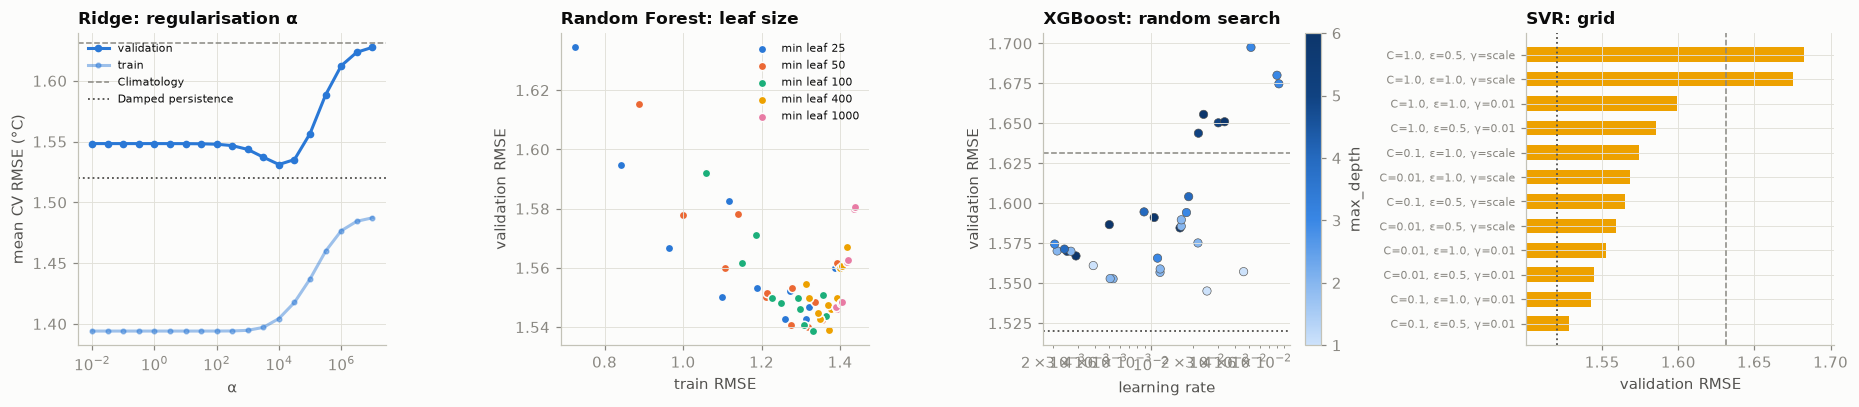

In [7]:
fig, axes = plt.subplots(1, 4, figsize=(17, 3.8))
clim_cv = cv_base[cv_base.model == "Climatology"].val_rmse.mean()
damp_cv = cv_base[cv_base.model == "Damped persistence"].val_rmse.mean()
def refs(ax):
    ax.axhline(clim_cv, color=V.MUTED, linestyle="--", linewidth=1, label="Climatology")
    ax.axhline(damp_cv, color=V.INK_2, linestyle=":", linewidth=1.2, label="Damped persistence")

r = cv_tables["Ridge"].sort_values("param_model__alpha")
ax = axes[0]; ax.plot(r["param_model__alpha"].astype(float), r["mean_val_rmse"], color=V.CATEGORICAL[0], marker="o", markersize=4, label="validation")
ax.plot(r["param_model__alpha"].astype(float), r["mean_train_rmse"], color=V.CATEGORICAL[0], alpha=.45, marker="o", markersize=3, label="train")
ax.set_xscale("log"); ax.set(title="Ridge: regularisation α", xlabel="α", ylabel="mean CV RMSE (°C)"); refs(ax); ax.legend(fontsize=7)

r = cv_tables["Random Forest"]
ax = axes[1]
for i, leaf in enumerate(sorted(r["param_min_samples_leaf"].unique())):
    s = r[r["param_min_samples_leaf"] == leaf]
    ax.scatter(s["mean_train_rmse"], s["mean_val_rmse"], s=30, color=V.CATEGORICAL[i], label=f"min leaf {leaf}", edgecolor=V.SURFACE)
ax.set(title="Random Forest: leaf size", xlabel="train RMSE", ylabel="validation RMSE"); ax.legend(fontsize=7)

r = cv_tables["XGBoost"]
ax = axes[2]
sc = ax.scatter(r["param_learning_rate"].astype(float), r["mean_val_rmse"], c=r["param_max_depth"].astype(int), cmap=V.SEQ_BLUE, s=30, edgecolor=V.INK_2, linewidth=.4)
ax.set_xscale("log"); ax.set(title="XGBoost: random search", xlabel="learning rate", ylabel="validation RMSE"); refs(ax)
fig.colorbar(sc, ax=ax, label="max_depth")

r = cv_tables["SVR"].reset_index(drop=True)
ax = axes[3]
lab = r.apply(lambda x: f"C={x['param_model__C']}, ε={x['param_model__epsilon']}, γ={x['param_model__gamma']}", axis=1)
ax.barh(lab, r["mean_val_rmse"], color=V.CATEGORICAL[3], height=.6)
ax.set_xlim(min(r["mean_val_rmse"].min(), damp_cv) - .02, r["mean_val_rmse"].max() + .02)
ax.axvline(clim_cv, color=V.MUTED, linestyle="--", linewidth=1); ax.axvline(damp_cv, color=V.INK_2, linestyle=":", linewidth=1.2)
ax.set(title="SVR: grid", xlabel="validation RMSE"); ax.tick_params(axis="y", labelsize=7)
fig.tight_layout(); V.save(fig, "ml_01_tuning_curves"); plt.show()

In [8]:
# Cross-validated comparison: every model's best configuration vs the baselines, per fold
per_fold = []
for name in M.MODEL_ORDER:
    best = cv_tables[name].iloc[0]
    for k in range(4):
        per_fold.append({"model": name, "fold": k + 1, "val_rmse": -best[f"split{k}_test_score"]})
cvcmp = pd.concat([cv_base[["model", "fold", "val_rmse"]], pd.DataFrame(per_fold)])
order = M.BASELINE_ORDER + M.MODEL_ORDER
tab = cvcmp.pivot(index="model", columns="fold", values="val_rmse").loc[order]
tab.columns = [f"fold {c}" for c in tab.columns]
tab["mean"] = tab.mean(axis=1)
tab["CV skill vs climatology"] = 1 - (tab["mean"] ** 2) / (tab.loc["Climatology", "mean"] ** 2)
tab.to_csv(C.ROOT / "reports" / "cv_comparison.csv")
tab.round(4)

,fold 1,fold 2,fold 3,fold 4,mean,CV skill vs climatology
model,,,,,,
Climatology,1.5627,1.6198,1.4670,1.8754,1.6312,0.0000
Persistence,1.7298,1.6958,1.7687,2.0239,1.8046,-0.2238
Damped persistence,1.4623,1.4988,1.4008,1.7182,1.5201,0.1317
Ridge,1.4803,1.5119,1.3750,1.7575,1.5312,0.1189
Random Forest,1.4957,1.5118,1.3575,1.7896,1.5387,0.1103
XGBoost,1.4836,1.5294,1.3566,1.8108,1.5451,0.1028
SVR,1.4572,1.5139,1.3388,1.8026,1.5281,0.1224


## 3b. Feature-group ablation (Ridge, same CV folds)

Which feature groups actually help? We refit the tuned Ridge **without** each group, and also with this month's anomaly alone. Ridge is used because it is fast and deterministic, so the differences are not random-seed noise.
A group whose removal *lowers* the RMSE is adding noise rather than signal.

In [9]:
def ridge_cv(cols):
    r = []
    for f in folds:
        m = M.make_model("Ridge").set_params(**best_params["Ridge"]).fit(f["train"][cols], f["train"][F.TARGET])
        r.append(np.sqrt(np.mean((m.predict(f["val"][cols]) - f["val"][F.TARGET]) ** 2)))
    return np.mean(r)
abl = {"All features": ridge_cv(F.FEATURES), "Only this month's anomaly (tmax_anom_l0)": ridge_cv(["tmax_anom_l0"])}
for g, cols in F.FEATURE_GROUPS.items():
    abl[f"All minus {g}"] = ridge_cv([c for c in F.FEATURES if c not in cols])
abl = pd.Series(abl, name="mean CV RMSE").to_frame()
abl["vs all features"] = abl["mean CV RMSE"] - abl.loc["All features", "mean CV RMSE"]
abl["vs damped persistence"] = abl["mean CV RMSE"] - damp_cv
abl.to_csv(C.ROOT / "reports" / "ablation_ridge.csv")
abl.round(4)

,mean CV RMSE,vs all features,vs damped persistence
All features,1.5312,0.0000,0.0111
Only this month's anomaly (tmax_anom_l0),1.5419,0.0107,0.0218
All minus Temperature memory,1.5295,-0.0017,0.0094
All minus Moisture memory,1.5296,-0.0015,0.0096
All minus Radiation,1.5328,0.0016,0.0127
All minus Large-scale context,1.5319,0.0007,0.0118
All minus Seasonal persistence,1.5374,0.0063,0.0174
All minus Seasonality,1.5299,-0.0012,0.0099
All minus Geography,1.5311,-0.0001,0.0110


## 4. Final fit on 2000–2022 and predictions

In [10]:
final_models, fit_secs = {}, {}
for name in M.MODEL_ORDER:
    t0 = time.time()
    final_models[name] = M.fit_model(name, best_params[name], dev)
    fit_secs[name] = time.time() - t0
    M.save_model(name, final_models[name])
pd.Series(fit_secs).round(1).rename("final fit time (s)").to_frame()

,final fit time (s)
Ridge,0.1
Random Forest,1.8
XGBoost,1.3
SVR,50.2


In [11]:
# Out-of-fold predictions (2011-2022), used in notebook 06 to choose the extreme-heat decision threshold
oof = M.oof_frame(folds)
for name in M.MODEL_ORDER:
    oof[name] = M.oof_predictions(name, best_params[name], folds)
oof.to_parquet(C.DATA_PROCESSED / "oof_predictions.parquet", index=False)
print("out-of-fold rows:", len(oof))

out-of-fold rows: 18144


In [12]:
# Test-set predictions: SAVED here, EVALUATED in notebook 06
pred = test[["district_id", "district", "province", "lat", "lon", "elevation_m", "target_date", "target_year", "target_month",
             "target_season", F.TARGET, "target_tmax", "target_tmax_clim", "tmax_anom_l0"]].copy()
for name, p in M.baseline_predictions(test, phi_dev).items():
    pred[name] = p
for name in M.MODEL_ORDER:
    pred[name] = final_models[name].predict(test[F.FEATURES])
pred.to_parquet(C.DATA_PROCESSED / "test_predictions.parquet", index=False)
with open(C.MODELS_DIR / "phi.txt", "w") as fh: fh.write(str(phi_dev))
print("saved", pred.shape)

saved (4536, 21)
